# Implementación de Regresión Logística con PyTorch
## Clasificación binaria de calidad de vino (BUENA / MALA)

**Curso:** Inteligencia Artificial
**Institución:** Instituto Tecnológico de Costa Rica — Escuela de Ingeniería en Computación
**Dataset:** Red Wine Quality (Cortez et al., 2009)

---

Este notebook implementa el flujo completo del proyecto:
1. Análisis exploratorio (EDA) y selección justificada de features.
2. Preparación de datos (split estratificado + estandarización).
3. Modelo de regresión logística en PyTorch.
4. 10 experimentos con diferentes hiperparámetros.
5. Selección del mejor modelo y evaluación final en test.

In [104]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# Resolver el proyecto tanto si el notebook se ejecuta desde la raíz como desde notebook/.
WORKSPACE = Path.cwd()
PROJECT_DIR = WORKSPACE if (WORKSPACE / "data").exists() else WORKSPACE.parent
DATA_DIR = PROJECT_DIR / "data"
FIG_DIR = PROJECT_DIR / "figuras"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

SEED = 42
THRESHOLD = 6
MAX_FEATURES = 6


def fijar_semilla(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


fijar_semilla()
sns.set_theme(style="whitegrid", context="notebook")

print("PyTorch:", torch.__version__)
print("Pandas:  ", pd.__version__)
print("NumPy:   ", np.__version__)
print("PROJECT_DIR:", PROJECT_DIR)

PyTorch: 2.14.1
Pandas:   3.0.6
NumPy:    2.5.3
PROJECT_DIR: /Users/danielmendez/Documents/GitHub/Tarea_IA_Logistic_Regression


## 1. Análisis Exploratorio de Datos (EDA)

El dataset Red Wine Quality contiene 1599 muestras de vinos tintos con 11 características fisicoquímicas y una variable `quality` en escala 3-9.

In [105]:
df_raw = pd.read_csv(os.path.join(DATA_DIR, "winequality-red.csv"))
df_raw.columns = [column.strip().strip('"') for column in df_raw.columns]

print(f"Shape original: {df_raw.shape}")
print(f"Valores nulos totales: {df_raw.isna().sum().sum()}")
print(f"Filas duplicadas: {df_raw.duplicated().sum()}")
print("\nTipos de datos:")
print(df_raw.dtypes.to_string())

quality_counts = df_raw["quality"].value_counts().sort_index()
print("Distribución original de quality:")
print(quality_counts)

# Los duplicados se eliminan antes del split para evitar fuga entre conjuntos.
df = df_raw.drop_duplicates().reset_index(drop=True).copy()
df["label"] = (df["quality"] >= 6).astype(int)

print(f"\nShape después de eliminar duplicados: {df.shape}")
print("Distribución binaria (0=MALA, 1=BUENA):")
print(df["label"].value_counts().sort_index())
print("Proporciones:")
print(df["label"].value_counts(normalize=True).sort_index().round(3))

Shape original: (1599, 12)
Valores nulos totales: 0
Filas duplicadas: 240

Tipos de datos:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Distribución original de quality:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Shape después de eliminar duplicados: (1359, 13)
Distribución binaria (0=MALA, 1=BUENA):
label
0    640
1    719
Name: count, dtype: int64
Proporciones:
label
0    0.471
1    0.529
Name: proportion, dtype: float64


In [106]:
num = df.select_dtypes(include="number")
ficha = pd.DataFrame({
    "dtype": df.dtypes.astype(str), "nulos": df.isna().sum(), "% nulos": (df.isna().mean() * 100).round(2),
    "únicos": df.nunique(), "ceros": (num == 0).sum(),
    "min": num.min(), "mediana": num.median(), "max": num.max(), "media": num.mean(), "std": num.std()})
display(ficha.round(3))

,dtype,nulos,% nulos,únicos,ceros,min,mediana,max,media,std
fixed acidity,float64,0,0.0,96,0,4.600,7.900,15.900,8.311,1.737
volatile acidity,float64,0,0.0,143,0,0.120,0.520,1.580,0.529,0.183
citric acid,float64,0,0.0,80,118,0.000,0.260,1.000,0.272,0.196
residual sugar,float64,0,0.0,91,0,0.900,2.200,15.500,2.523,1.352
chlorides,float64,0,0.0,153,0,0.012,0.079,0.611,0.088,0.049
free sulfur dioxide,float64,0,0.0,60,0,1.000,14.000,72.000,15.893,10.447
total sulfur dioxide,float64,0,0.0,144,0,6.000,38.000,289.000,46.826,33.409
density,float64,0,0.0,436,0,0.990,0.997,1.004,0.997,0.002
pH,float64,0,0.0,89,0,2.740,3.310,4.010,3.310,0.155
sulphates,float64,0,0.0,96,0,0.330,0.620,2.000,0.659,0.171


### D. Escalas y balance de clases 

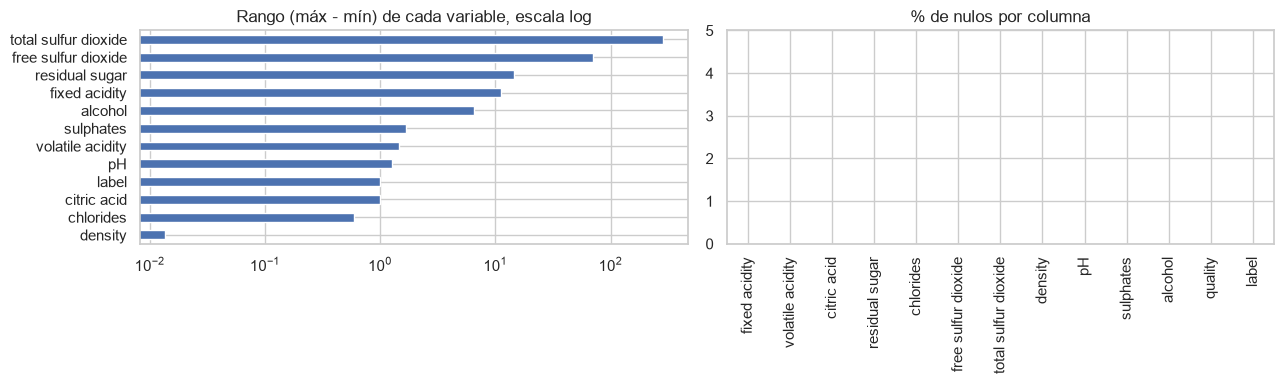

In [107]:
feats = num.drop(columns=[c for c in ["quality"] if c in num])
rangos = (feats.max() - feats.min())                  # cuánto varía cada variable
pct_buena = (df["quality"] >= THRESHOLD).mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
rangos.sort_values().plot.barh(ax=ax[0], logx=True, color="#4C72B0"); ax[0].set_title("Rango (máx - mín) de cada variable, escala log")
(df.isna().mean() * 100).plot.bar(ax=ax[1], color="#C44E52"); ax[1].set_title("% de nulos por columna"); ax[1].set_ylim(0, 5)
plt.tight_layout(); plt.show()

### Interpretacion de resultados:

1) Tamaño: 1599 filas y 11 variables predictoras. Hay datos suficientes para un modelo sencillo.
2) Nulos: 0. No hace falta rellenar datos.
3) Duplicados: 240 (15.0%). Se eliminarán antes de dividir los datos.
4) Columnas constantes: ninguna (una columna con un solo valor no sirve para predecir).
5) Variables con pocos valores distintos: ['quality']. 'quality' es un puntaje entero, así que la convertiremos en BUENA/MALA.
6) Valores negativos: ninguno (no deberían existir en estas mediciones).
7) pH va de 2.74 a 4.01: valores razonables para un vino.
8) Escalas: 'total sulfur dioxide' varía en un rango de 283.0, mientras que 'density' solo en 0.014. Como son tan distintas, las pondremos en la misma escala (estandarizar) antes de entrenar.
9) Balance: 53% de los vinos son BUENA y 47% MALA (con umbral 6). Las clases están parecidas en tamaño.

Variable objetivo (feature engineering sobre `quality`)

`quality` es una puntuación ordinal (≈3 a 8). Para un problema binario hay que elegir un umbral. Se compara el balance de clases
para cada posible corte antes de decidir.

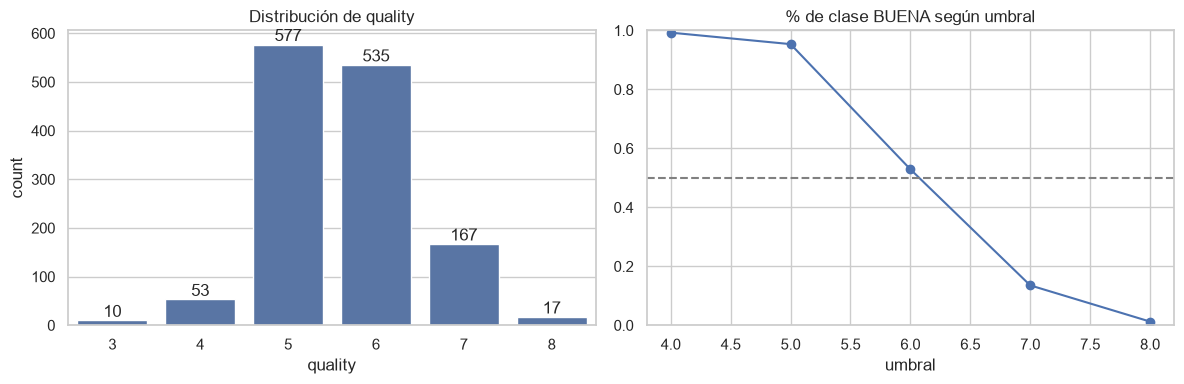

,umbral (>=),% BUENA,n BUENA,n MALA
0,4,0.993,1349,10
1,5,0.954,1296,63
2,6,0.529,719,640
3,7,0.135,184,1175
4,8,0.013,17,1342


In [108]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="quality", data=df, ax=ax[0], color="#4C72B0")
ax[0].set_title("Distribución de quality")
for v in ax[0].containers: ax[0].bar_label(v)

rows = [(t, (df.quality >= t).mean(), (df.quality >= t).sum(), (df.quality < t).sum()) for t in sorted(df.quality.unique())[1:]]
tab = pd.DataFrame(rows, columns=["umbral (>=)", "% BUENA", "n BUENA", "n MALA"])
ax[1].plot(tab["umbral (>=)"], tab["% BUENA"], "o-"); ax[1].axhline(0.5, ls="--", c="gray")
ax[1].set_title("% de clase BUENA según umbral"); ax[1].set_xlabel("umbral"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()
display(tab.round(3))

**Interpretación.** `quality` se concentra en pocos valores centrales (5 y 6), con colas muy delgadas. Un umbral de 6 produce clases
aproximadamente balanceadas; un umbral de 7 produce una clase positiva minoritaria (~10-15 %), lo que exigiría métricas como
F1/PR-AUC y *stratified sampling* de forma crítica.

> `quality` debe **excluirse** de las predictoras: el target se deriva directamente de ella (fuga de información).

In [109]:
df["target"] = (df["quality"] >= THRESHOLD).astype(int)   # 1 = BUENA, 0 = MALA
raw_features = [c for c in df.columns if c not in ("quality", "target")]
print("Predictoras candidatas:", raw_features)
print(df["target"].value_counts().rename({0: "MALA", 1: "BUENA"}))
print(f"Proporción BUENA: {df.target.mean():.3f}")

Predictoras candidatas: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'label']
target
BUENA    719
MALA     640
Name: count, dtype: int64
Proporción BUENA: 0.529


### 1.1. Distribuciones y correlaciones

Histogramas, boxplots y matriz de correlación de las 11 características fisicoquímicas.

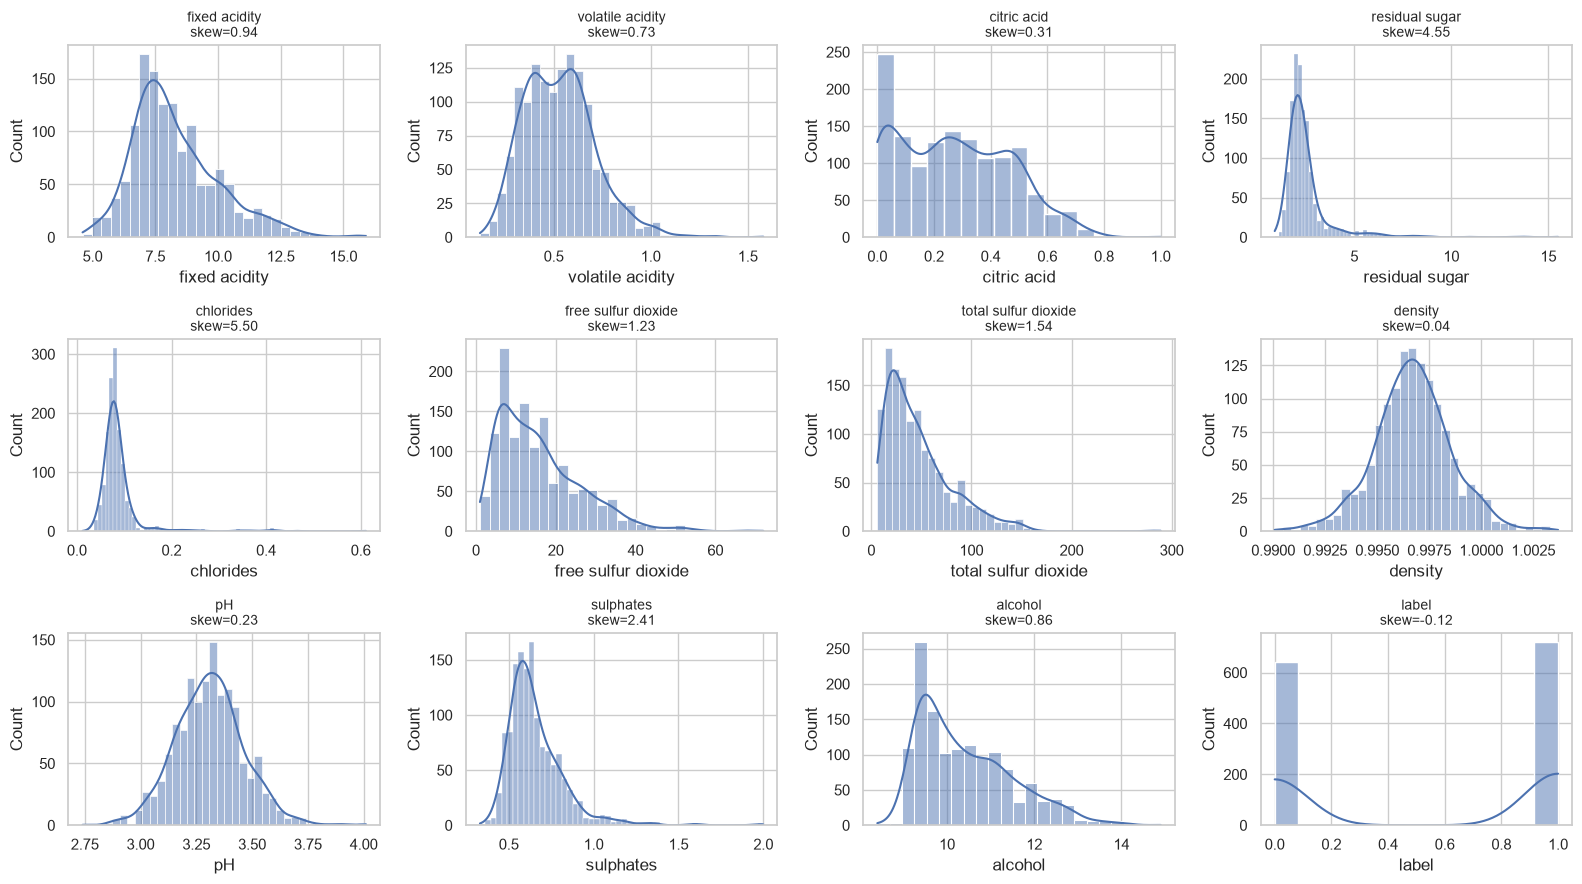

,skewness,kurtosis
chlorides,5.50,38.62
residual sugar,4.55,29.36
sulphates,2.41,11.10
total sulfur dioxide,1.54,4.04
free sulfur dioxide,1.23,1.89
fixed acidity,0.94,1.05
alcohol,0.86,0.16
volatile acidity,0.73,1.25
citric acid,0.31,-0.79
pH,0.23,0.88


In [110]:
def grid(n, ncols=4, h=3):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, h * nrows))
    axes = np.atleast_1d(axes).ravel()
    for a in axes[n:]: a.axis("off")
    return fig, axes

fig, axes = grid(len(raw_features))
for a, c in zip(axes, raw_features):
    sns.histplot(df[c], kde=True, ax=a, color="#4C72B0")
    a.set_title(f"{c}\nskew={df[c].skew():.2f}", fontsize=10)
plt.tight_layout(); plt.show()

skew_tab = df[raw_features].skew().sort_values(ascending=False).to_frame("skewness")
skew_tab["kurtosis"] = df[raw_features].kurt()
display(skew_tab.round(2))

**Interpretación.** Variables con asimetría |skew| > 1 (típicamente `residual sugar`, `chlorides`, `sulphates`,
`total sulfur dioxide`) tienen colas largas a la derecha. En regresión logística no se exige normalidad de las predictoras,
pero las colas pesadas hacen que unos pocos puntos dominen el gradiente y los coeficientes; una transformación logarítmica lo mitiga
(sección 5).

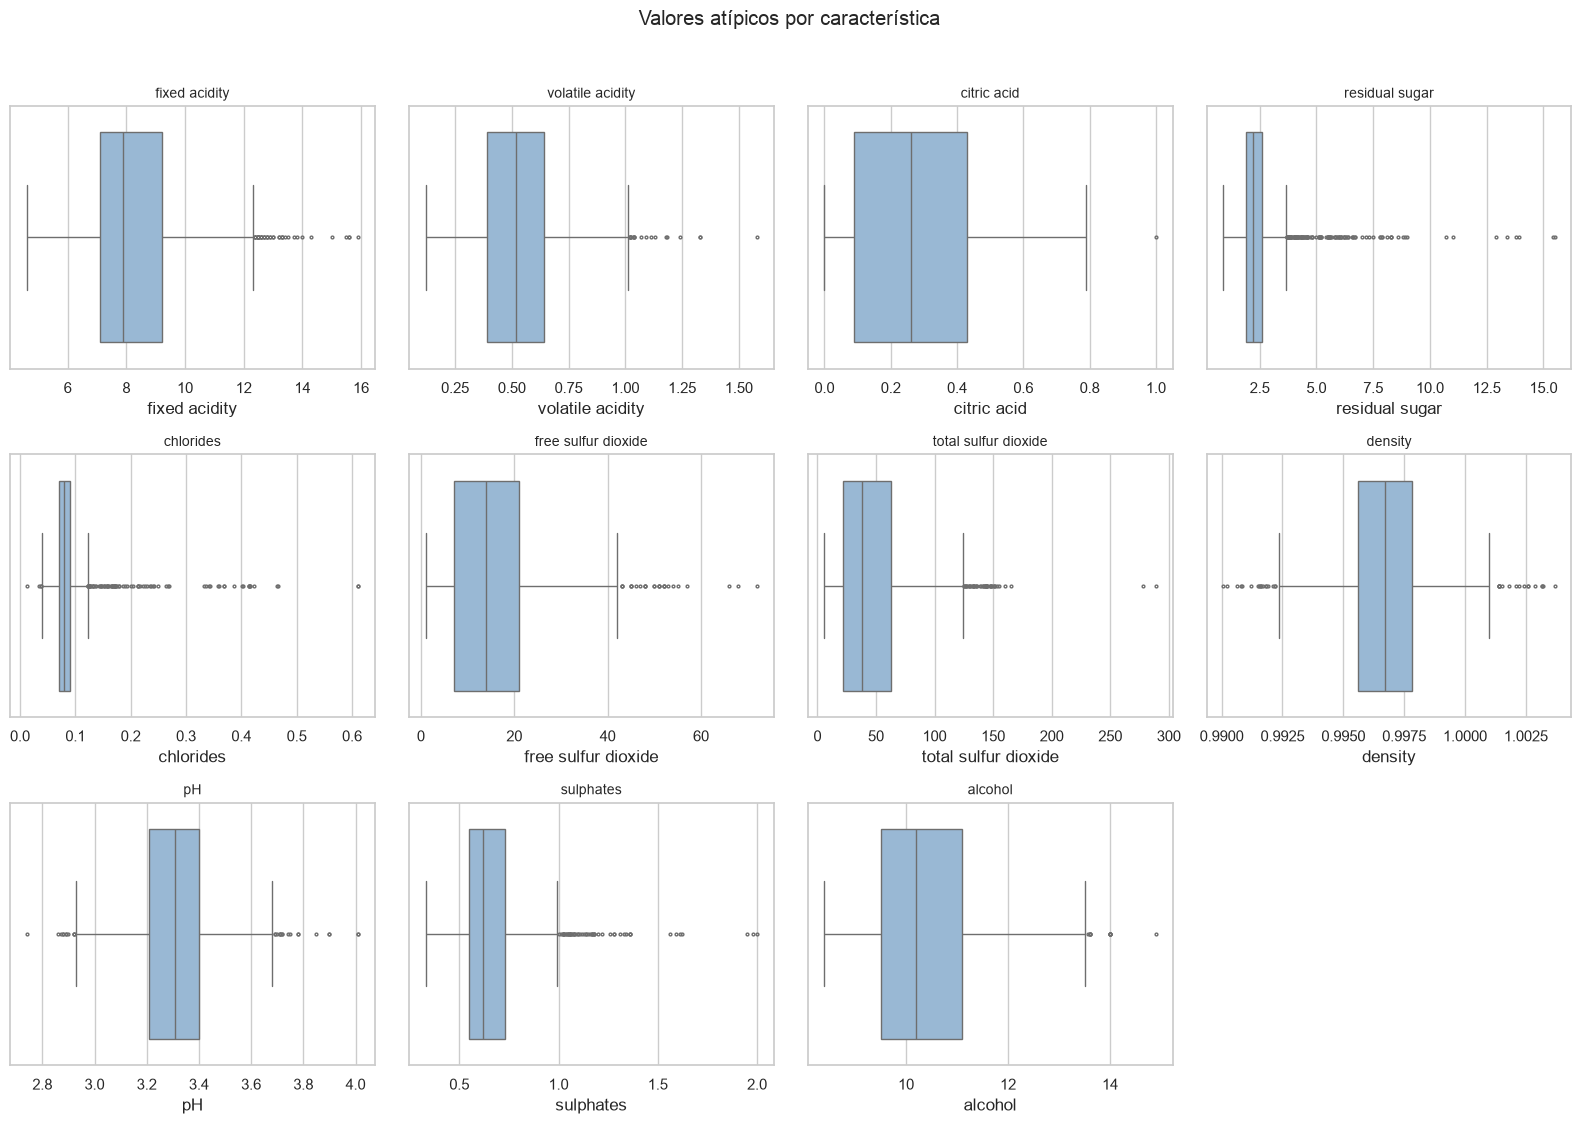

,n_outliers_IQR,%
residual sugar,126,9.27
chlorides,87,6.40
sulphates,55,4.05
total sulfur dioxide,45,3.31
fixed acidity,41,3.02
density,35,2.58
pH,28,2.06
free sulfur dioxide,26,1.91
volatile acidity,19,1.40
alcohol,12,0.88


In [111]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.ravel()
for axis, feature in zip(axes, features_all):
    sns.boxplot(x=df[feature], ax=axis, color="#8FB8DE", fliersize=2)
    axis.set_title(feature, fontsize=10)
for axis in axes[len(features_all):]:
    axis.axis("off")
plt.suptitle("Valores atípicos por característica", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "boxplots.png"), dpi=120)
plt.show()

q1 = df[features_all].quantile(0.25)
q3 = df[features_all].quantile(0.75)
iqr = q3 - q1
outlier_count = ((df[features_all] < q1 - 1.5 * iqr) |
                 (df[features_all] > q3 + 1.5 * iqr)).sum()
outlier_table = pd.DataFrame({
    "n_outliers_IQR": outlier_count,
    "%": (outlier_count / len(df) * 100).round(2),
}).sort_values("%", ascending=False)
display(outlier_table)

**Interpretación.** Los puntos fuera de 1.5·IQR son frecuentes en las variables asimétricas. No se eliminan: en este dominio
son vinos reales (no errores de medición evidentes) y eliminarlos reduciría muestra. En su lugar se atenúan con `log1p`
y con estandarización.

### 3.3 Relación de cada variable con el target

/var/folders/1t/lqyl48ks4cgdjy4tzmbf8vlc0000gn/T/ipykernel_19628/1526202839.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="target", y=c, ax=a, palette=["#C44E52", "#55A868"], inner="quartile", cut=0)
/var/folders/1t/lqyl48ks4cgdjy4tzmbf8vlc0000gn/T/ipykernel_19628/1526202839.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  a.set_xticklabels(["MALA", "BUENA"]); a.set_xlabel(""); a.set_title(c, fontsize=10)
/var/folders/1t/lqyl48ks4cgdjy4tzmbf8vlc0000gn/T/ipykernel_19628/1526202839.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="tar

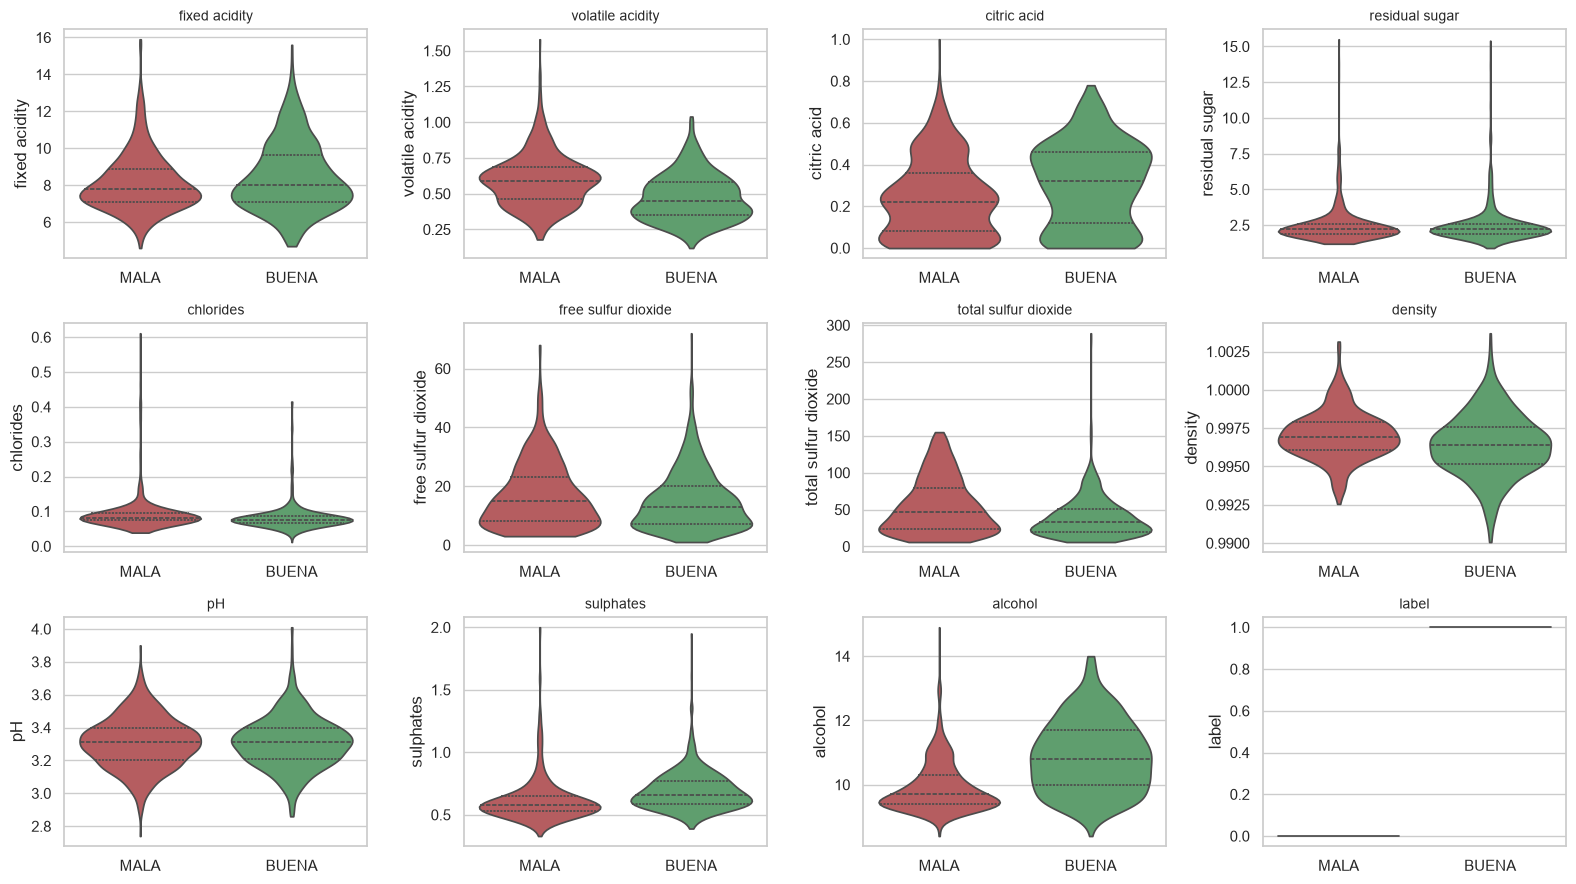

In [112]:
fig, axes = grid(len(raw_features))
for a, c in zip(axes, raw_features):
    sns.violinplot(data=df, x="target", y=c, ax=a, palette=["#C44E52", "#55A868"], inner="quartile", cut=0)
    a.set_xticklabels(["MALA", "BUENA"]); a.set_xlabel(""); a.set_title(c, fontsize=10)
plt.tight_layout(); plt.show()

Los resultados del análisis exploratorio muestran que **alcohol**, **densidad**, **ácido cítrico** y **acidez volátil** presentan una relación relevante con la calidad del vino. En especifico, los vinos clasificados como **BUENOS** tienden a presentar mayor contenido de alcohol y ácido cítrico, mientras que una mayor acidez volátil se puede ver con vinos de menor calidad o **MALA**. 

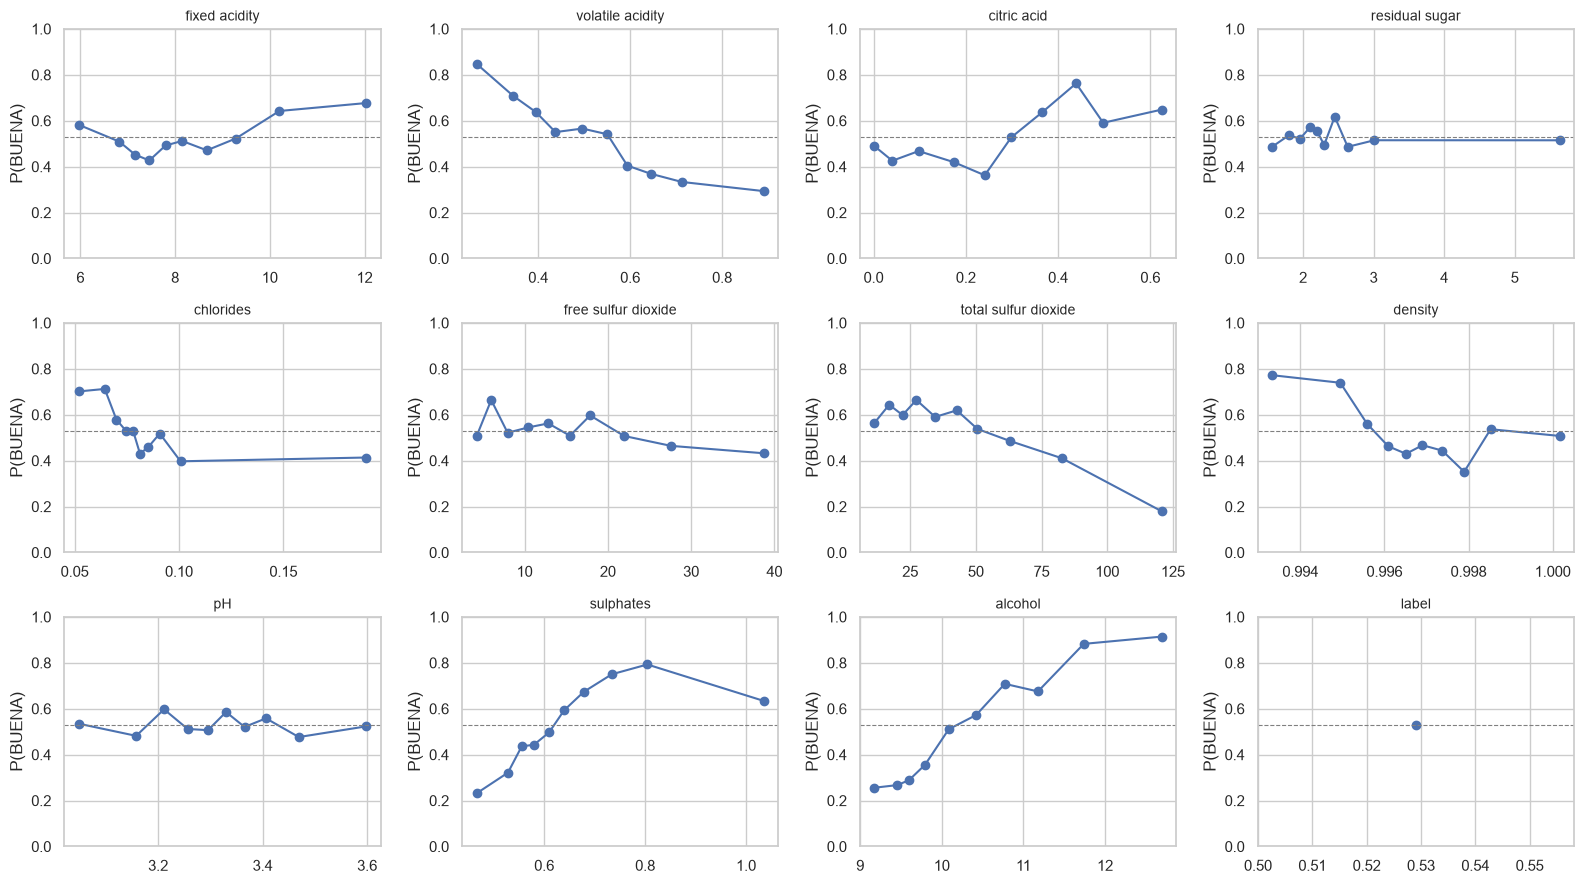

In [113]:
# Dispersión vs target binario: probabilidad empírica de BUENA por deciles de cada variable
# (si la relación es monótona, el modelo logístico es apropiado)
fig, axes = grid(len(raw_features))
for a, c in zip(axes, raw_features):
    b = pd.qcut(df[c], 10, duplicates="drop")
    g = df.groupby(b, observed=True).agg(x=(c, "mean"), p=("target", "mean"))
    a.plot(g.x, g.p, "o-"); a.set_ylim(0, 1); a.axhline(df.target.mean(), ls="--", c="gray", lw=.8)
    a.set_title(c, fontsize=10); a.set_ylabel("P(BUENA)")
plt.tight_layout(); plt.show()

**Interpretación.** Las curvas monótonas y con pendiente marcada (p. ej. `alcohol` creciente, `volatile acidity` decreciente)
indican predictores informativos con relación aproximadamente logit-lineal. Curvas planas sobre la línea punteada
(media global) indican poca señal individual (p. ej. `residual sugar`, `free sulfur dioxide`, `pH` suelen ser débiles).

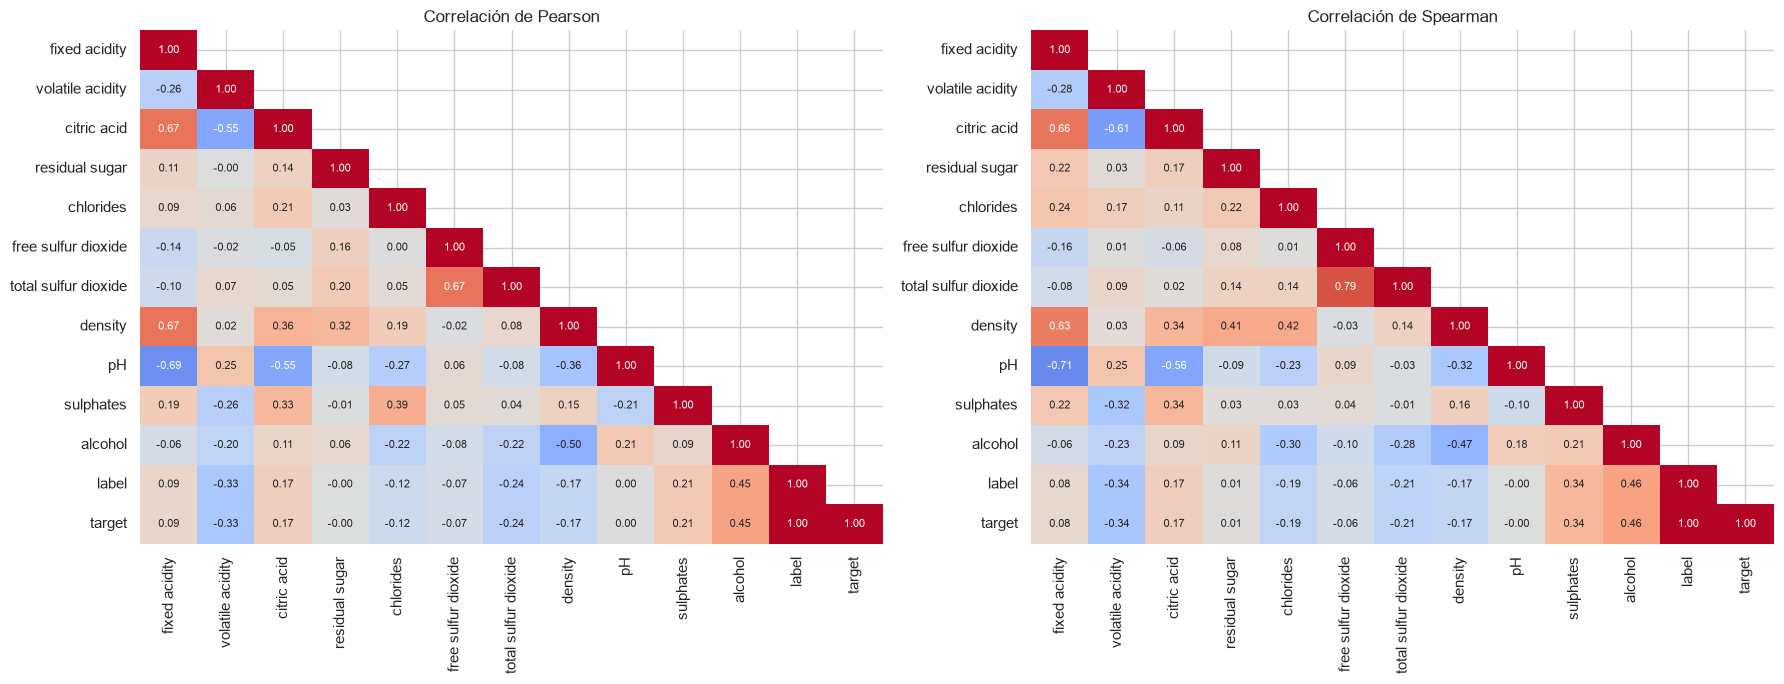

Correlación con el target (Pearson = punto-biserial):


,r
label,1.000
alcohol,0.446
volatile acidity,-0.327
total sulfur dioxide,-0.235
sulphates,0.211
density,-0.169
citric acid,0.168
chlorides,-0.115
fixed acidity,0.092
free sulfur dioxide,-0.069


In [114]:
corr_p = df[raw_features + ["target"]].corr(method="pearson")
corr_s = df[raw_features + ["target"]].corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for a, m, t in zip(ax, [corr_p, corr_s], ["Pearson", "Spearman"]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
                mask=np.triu(np.ones_like(m, dtype=bool), 1), ax=a, annot_kws={"size": 8}, cbar=False)
    a.set_title(f"Correlación de {t}")
plt.tight_layout(); plt.show()

print("Correlación con el target (Pearson = punto-biserial):")
display(corr_p["target"].drop("target").sort_values(key=abs, ascending=False).to_frame("r").round(3))

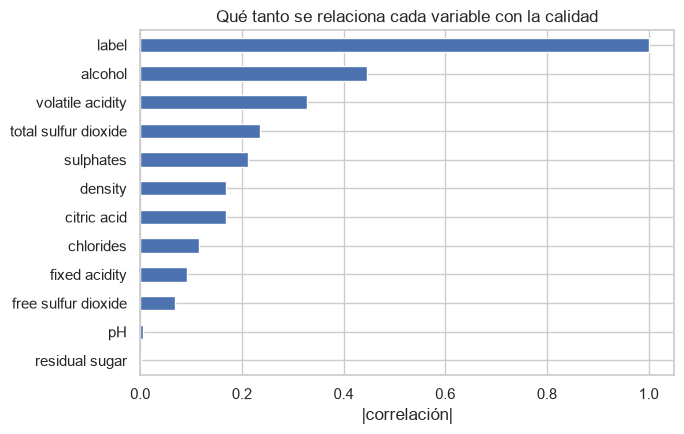

In [115]:
corr_target = corr_p["target"].drop("target").abs().sort_values()

corr_target.plot.barh(figsize=(7, 4.5), color="#4C72B0")
plt.xlabel("|correlación|")
plt.title("Qué tanto se relaciona cada variable con la calidad")
plt.tight_layout()
plt.show()

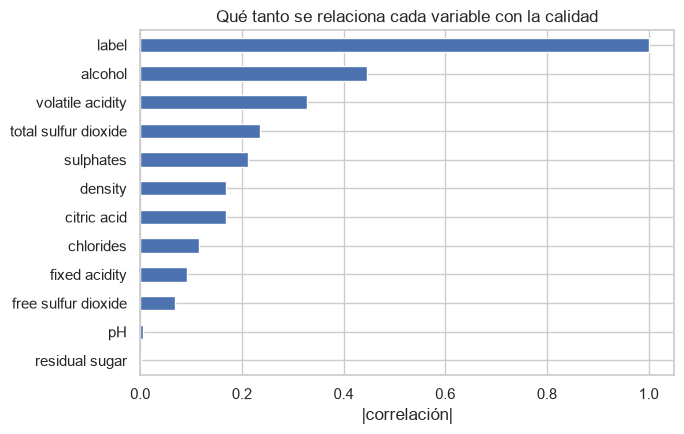

In [116]:
corr_target = corr_p["target"].drop("target").abs().sort_values()

corr_target.plot.barh(figsize=(7, 4.5), color="#4C72B0")
plt.xlabel("|correlación|")
plt.title("Qué tanto se relaciona cada variable con la calidad")
plt.tight_layout()
plt.show()

**Interpretación.** Dos hallazgos que guían la selección:

* **Relevancia:** las variables con mayor |r| con el target (típicamente `alcohol`, `volatile acidity`, `sulphates`, `citric acid`)
  son candidatas naturales.
* **Redundancia:** pares como `fixed acidity`–`pH`, `fixed acidity`–`density`, `fixed acidity`–`citric acid` y
  `free`–`total sulfur dioxide` están muy correlacionados. Si dejo las dos, estoy repitiendo casi la misma información.
  En la sección 6 me quedo solo con una de cada par.

## 2. Selección justificada de features

Se aplican dos criterios complementarios sobre las 11 características:

1. **Correlación de Pearson** con la etiqueta binaria (captura relaciones lineales).
2. **Información mutua** $I(X;Y)$ estimada por discretización en cuantiles (captura relaciones no lineales).

Además, se verifica la **multicolinealidad** entre features para evitar redundancia.

In [117]:
# Función de información mutua manual (por discretización)
def mutual_info_manual(x, y, n_bins=10):
    x_disc = pd.qcut(x, q=n_bins, labels=False, duplicates='drop')
    joint = pd.crosstab(x_disc, y, normalize=True)
    px = joint.sum(axis=1); py = joint.sum(axis=0)
    mi = 0.0
    for i in joint.index:
        for j in joint.columns:
            pxy = joint.loc[i, j]
            if pxy > 0:
                mi += pxy * np.log(pxy / (px[i] * py[j]))
    return mi

mi_results = {f: mutual_info_manual(df[f], df['label']) for f in features_all}
mi_series = pd.Series(mi_results).sort_values(ascending=False)
corr_label = df[features_all].corrwith(df['label']).abs().sort_values(ascending=False)

summary = pd.DataFrame({
    'Correlación |r| con label': corr_label,
    'Información Mutua (MI)': mi_series
}).sort_values('Información Mutua (MI)', ascending=False)

print("=== Ranking combinado ===")
print(summary.round(4))

=== Ranking combinado ===
                      Correlación |r| con label  Información Mutua (MI)
alcohol                                  0.4462                  0.1217
sulphates                                0.2114                  0.0658
volatile acidity                         0.3272                  0.0617
total sulfur dioxide                     0.2350                  0.0389
density                                  0.1690                  0.0329
citric acid                              0.1679                  0.0282
chlorides                                0.1151                  0.0233
fixed acidity                            0.0918                  0.0119
free sulfur dioxide                      0.0692                  0.0074
residual sugar                           0.0024                  0.0032
pH                                       0.0047                  0.0029


In [118]:
corr_features = df[features_all].corr()
upper = corr_features.where(np.triu(np.ones(corr_features.shape), k=1).astype(bool))
pairs = upper.stack().reset_index()
pairs.columns = ['Feature 1', 'Feature 2', 'r']
pairs['abs_r'] = pairs['r'].abs()
pairs = pairs.sort_values('abs_r', ascending=False)

print("Pares con |r| > 0.5 (candidatos a multicolinealidad):")
print(pairs[pairs['abs_r'] > 0.5].to_string(index=False))

Pares con |r| > 0.5 (candidatos a multicolinealidad):
          Feature 1            Feature 2         r    abs_r
      fixed acidity                   pH -0.686685 0.686685
      fixed acidity              density  0.670195 0.670195
      fixed acidity          citric acid  0.667437 0.667437
free sulfur dioxide total sulfur dioxide  0.667246 0.667246
   volatile acidity          citric acid -0.551248 0.551248
        citric acid                   pH -0.550310 0.550310
            density              alcohol -0.504995 0.504995


### Decisión final

Combinando ambos criterios, las **6 features seleccionadas** son:

1. `alcohol`
2. `sulphates`
3. `volatile acidity`
4. `total sulfur dioxide`
5. `density`
6. `citric acid`

Ambos rankings (Pearson y MI) coinciden en el mismo conjunto. Ningún par dentro de las 6 supera $|r| = 0.7$, por lo que no hay que eliminar ninguna por redundancia.

## 3. Preparación de datos

Split estratificado 70/15/15 (train/val/test) y estandarización ajustada **solo** con el conjunto de entrenamiento (para evitar data leakage).

In [119]:
selected_features = ["alcohol", "sulphates", "volatile acidity",
                     "total sulfur dioxide", "density", "citric acid"]

X = df[selected_features].to_numpy(dtype="float32")
y = df["label"].to_numpy(dtype="int64")

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

split_summary = pd.DataFrame({
    "n": [len(y_train), len(y_val), len(y_test)],
    "% BUENA": [y_train.mean(), y_val.mean(), y_test.mean()],
    "% MALA": [1 - y_train.mean(), 1 - y_val.mean(), 1 - y_test.mean()],
}, index=["train", "val", "test"])
print(split_summary.round(3))

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train).astype("float32")
X_val_s = scaler.transform(X_val).astype("float32")
X_test_s = scaler.transform(X_test).astype("float32")

X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_val_t = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)
y_test_t = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

n_pos = (y_train_t == 1).sum().item()
n_neg = (y_train_t == 0).sum().item()
POS_WEIGHT = torch.tensor([n_neg / n_pos], dtype=torch.float32)

print("\nMedia de train:", X_train_s.mean(axis=0).round(3))
print("Desviación de train:", X_train_s.std(axis=0).round(3))
print(f"pos_weight: {POS_WEIGHT.item():.4f}")

         n  % BUENA  % MALA
train  951    0.529   0.471
val    204    0.529   0.471
test   204    0.529   0.471

Media de train: [-0.  0. -0.  0.  0.  0.]
Desviación de train: [1. 1. 1. 1. 1. 1.]
pos_weight: 0.8907


## 4. Modelo de regresión logística

Se implementa una regresión logística como `nn.Linear(input_dim, 1)` que devuelve **logits** (sin sigmoide). La función de pérdida `BCEWithLogitsLoss` aplica la sigmoide internamente de manera numéricamente estable.

In [120]:
class LogisticRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, 1)

    def forward(self, x):
        return self.linear(x)   # logits


def make_loaders(batch_size):
    tr = DataLoader(TensorDataset(X_train_t, y_train_t),
                    batch_size=batch_size, shuffle=True)
    va = DataLoader(TensorDataset(X_val_t, y_val_t),
                    batch_size=batch_size, shuffle=False)
    return tr, va


def train_model(model, train_loader, val_loader, criterion, optimizer, epochs):
    train_losses, val_losses = [], []
    for _ in range(epochs):
        model.train()
        tl = 0.0
        for bx, by in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
            tl += loss.item()
        train_losses.append(tl / len(train_loader))

        model.eval()
        vl = 0.0
        with torch.no_grad():
            for bx, by in val_loader:
                vl += criterion(model(bx), by).item()
        val_losses.append(vl / len(val_loader))
    return train_losses, val_losses


def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        probs = torch.sigmoid(model(X).squeeze(1)).numpy()
        preds = (probs > 0.5).astype(int)
    y_np = y.squeeze(1).numpy().astype(int)
    return {
        'accuracy': accuracy_score(y_np, preds),
        'precision': precision_score(y_np, preds, zero_division=0),
        'recall': recall_score(y_np, preds, zero_division=0),
        'f1': f1_score(y_np, preds, zero_division=0),
        'auc': roc_auc_score(y_np, probs),
    }, probs, preds, y_np

## 5. Diez experimentos con hiperparámetros

Se ejecutan 10 entrenamientos variando **optimizador, learning rate, batch size y épocas**. El criterio de selección es el **F1** en validación, con desempate por **AUC**.

Exp  1 | SGD  | lr=0.01  | batch= 32 | ep=100 → F1=0.7236 | AUC=0.8285


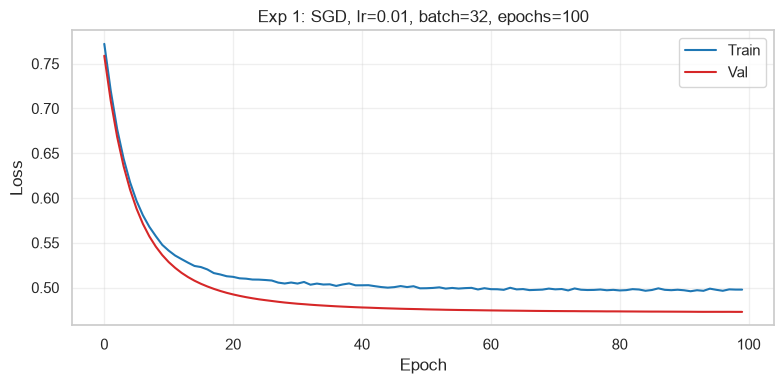

Exp  2 | SGD  | lr=0.001 | batch= 32 | ep=100 → F1=0.7041 | AUC=0.8007


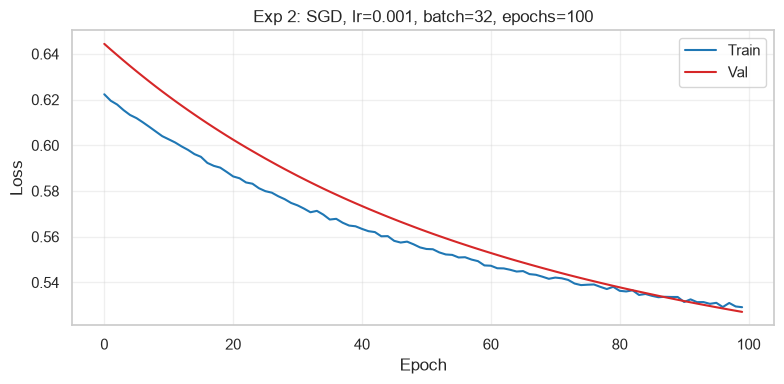

Exp  3 | SGD  | lr=0.1   | batch= 32 | ep=100 → F1=0.7264 | AUC=0.8302


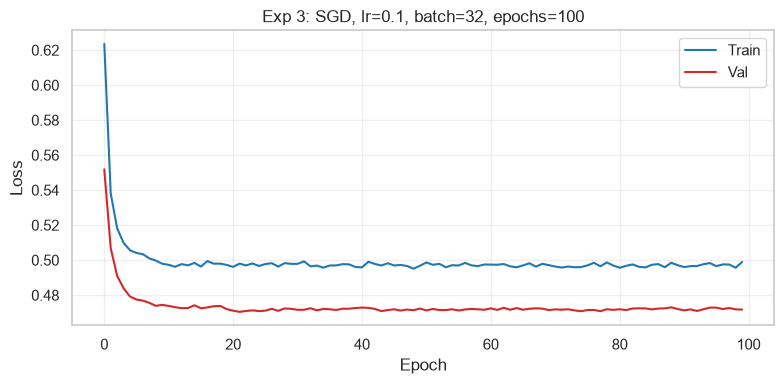

Exp  4 | SGD  | lr=0.01  | batch= 16 | ep=100 → F1=0.7200 | AUC=0.8301


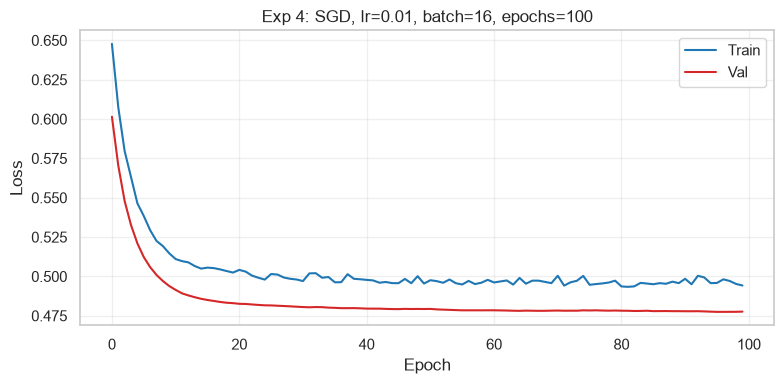

Exp  5 | SGD  | lr=0.01  | batch= 64 | ep=100 → F1=0.7129 | AUC=0.8275


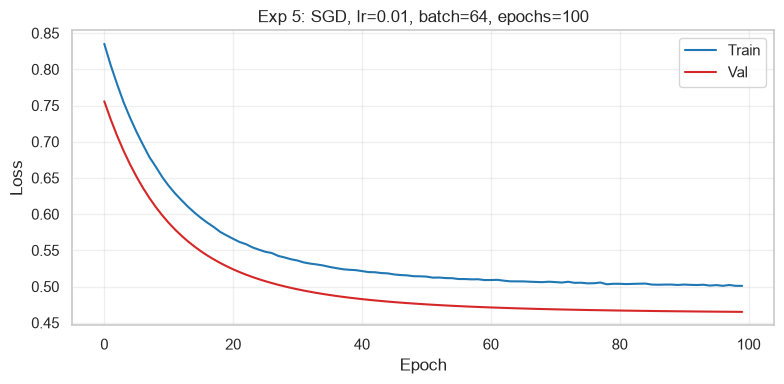

Exp  6 | SGD  | lr=0.01  | batch= 32 | ep=200 → F1=0.7200 | AUC=0.8300


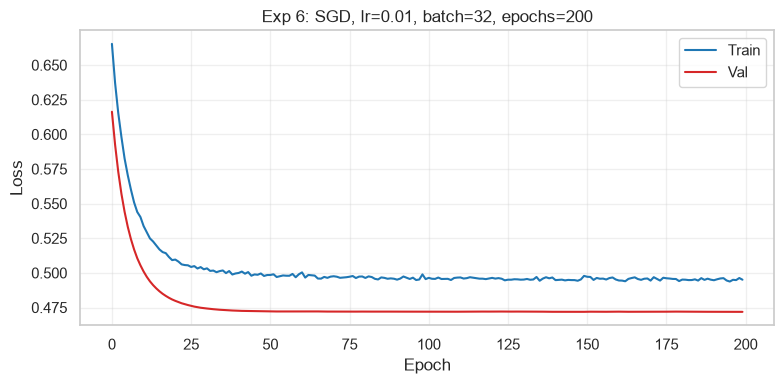

Exp  7 | Adam | lr=0.001 | batch= 32 | ep=100 → F1=0.7200 | AUC=0.8285


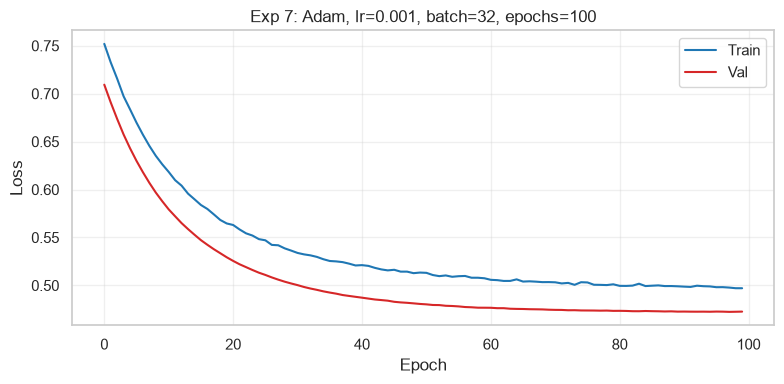

Exp  8 | Adam | lr=0.01  | batch= 32 | ep=100 → F1=0.7264 | AUC=0.8302


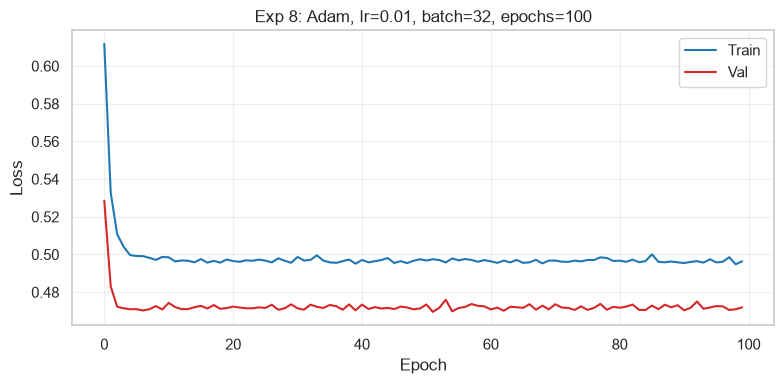

Exp  9 | Adam | lr=0.001 | batch= 16 | ep=150 → F1=0.7264 | AUC=0.8303


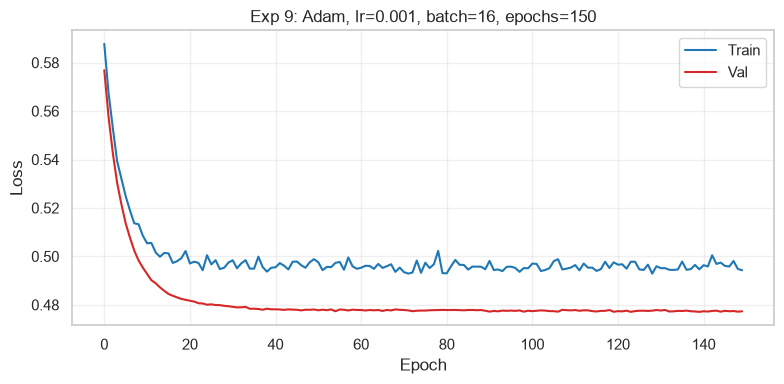

Exp 10 | Adam | lr=0.001 | batch= 64 | ep=150 → F1=0.7200 | AUC=0.8294


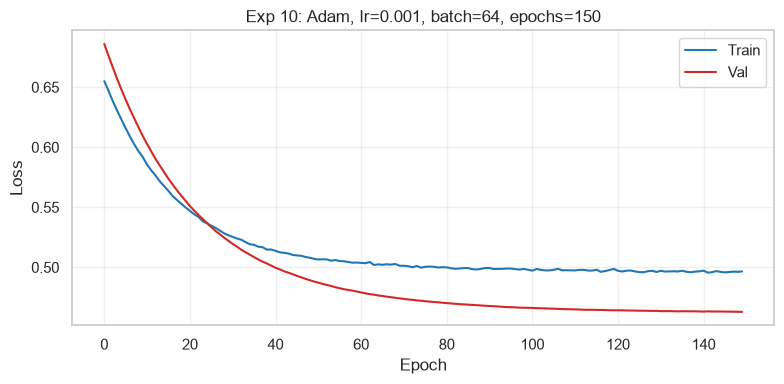


=== Tabla comparativa ===
 Exp Optimizer    LR  Batch  Epochs  Train Loss  Val Loss  Accuracy  Precision  Recall     F1    AUC
   3       SGD 0.100     32     100      0.4989    0.4717    0.7304     0.7849  0.6759 0.7264 0.8302
   8      Adam 0.010     32     100      0.4964    0.4719    0.7304     0.7849  0.6759 0.7264 0.8302
   9      Adam 0.001     16     150      0.4943    0.4773    0.7304     0.7849  0.6759 0.7264 0.8303
   1       SGD 0.010     32     100      0.4977    0.4729    0.7304     0.7912  0.6667 0.7236 0.8285
   4       SGD 0.010     16     100      0.4942    0.4776    0.7255     0.7826  0.6667 0.7200 0.8301
   6       SGD 0.010     32     200      0.4951    0.4719    0.7255     0.7826  0.6667 0.7200 0.8300
   7      Adam 0.001     32     100      0.4971    0.4727    0.7255     0.7826  0.6667 0.7200 0.8285
  10      Adam 0.001     64     150      0.4966    0.4629    0.7255     0.7826  0.6667 0.7200 0.8294
   5       SGD 0.010     64     100      0.5009    0.4650    0.7

In [121]:
experimentos = [
    (1,  'SGD',  0.01,  32, 100),
    (2,  'SGD',  0.001, 32, 100),
    (3,  'SGD',  0.1,   32, 100),
    (4,  'SGD',  0.01,  16, 100),
    (5,  'SGD',  0.01,  64, 100),
    (6,  'SGD',  0.01,  32, 200),
    (7,  'Adam', 0.001, 32, 100),
    (8,  'Adam', 0.01,  32, 100),
    (9,  'Adam', 0.001, 16, 150),
    (10, 'Adam', 0.001, 64, 150),
]

resultados = []
mejor_f1, mejor_auc = -1.0, -1.0
mejor_modelo, mejor_config = None, None

for exp_id, opt_name, lr, batch, epochs in experimentos:
    torch.manual_seed(42 + exp_id)
    tr_loader, va_loader = make_loaders(batch)
    model = LogisticRegressionModel(X_train_t.shape[1])
    criterion = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)
    optimizer = (torch.optim.SGD(model.parameters(), lr=lr) if opt_name == 'SGD'
                 else torch.optim.Adam(model.parameters(), lr=lr))

    tr_losses, vl_losses = train_model(model, tr_loader, va_loader,
                                        criterion, optimizer, epochs)

    metrics, _, _, _ = evaluate(model, X_val_t, y_val_t)
    print(f"Exp {exp_id:2d} | {opt_name:4s} | lr={lr:<5} | batch={batch:3d} "
          f"| ep={epochs:3d} → F1={metrics['f1']:.4f} | AUC={metrics['auc']:.4f}")

    resultados.append({
        'Exp': exp_id, 'Optimizer': opt_name, 'LR': lr,
        'Batch': batch, 'Epochs': epochs,
        'Train Loss': tr_losses[-1], 'Val Loss': vl_losses[-1],
        'Accuracy': metrics['accuracy'], 'Precision': metrics['precision'],
        'Recall': metrics['recall'], 'F1': metrics['f1'], 'AUC': metrics['auc'],
    })

    # Desempate por AUC
    if (metrics['f1'] > mejor_f1) or \
       (abs(metrics['f1'] - mejor_f1) < 1e-6 and metrics['auc'] > mejor_auc):
        mejor_f1, mejor_auc = metrics['f1'], metrics['auc']
        mejor_modelo = {k: v.clone() for k, v in model.state_dict().items()}
        mejor_config = (exp_id, opt_name, lr, batch, epochs)

    # Curva
    plt.figure(figsize=(8, 4))
    plt.plot(tr_losses, label='Train', color='tab:blue')
    plt.plot(vl_losses, label='Val',   color='tab:red')
    plt.xlabel('Epoch'); plt.ylabel('Loss')
    plt.title(f'Exp {exp_id}: {opt_name}, lr={lr}, batch={batch}, epochs={epochs}')
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"loss_exp{exp_id:02d}.png"), dpi=120)
    plt.show()

df_results = pd.DataFrame(resultados).sort_values('F1', ascending=False).reset_index(drop=True)
print("\n=== Tabla comparativa ===")
print(df_results.round(4).to_string(index=False))

print(f"\n Mejor modelo: Exp {mejor_config[0]} ({mejor_config[1]}, lr={mejor_config[2]}, "
      f"batch={mejor_config[3]}, epochs={mejor_config[4]})")
print(f"   F1 val:  {mejor_f1:.4f}")
print(f"   AUC val: {mejor_auc:.4f}")

## 6. Evaluación final en el conjunto de test

Se evalúa el mejor modelo (según validación) sobre el conjunto de **test**, que nunca fue visto durante el entrenamiento ni la selección de hiperparámetros.

In [122]:
# Reconstruir el mejor modelo y cargar pesos
model_final = LogisticRegressionModel(X_train_t.shape[1])
model_final.load_state_dict(mejor_modelo)
model_final.eval()

m_tr, _, _, _ = evaluate(model_final, X_train_t, y_train_t)
m_va, _, _, _ = evaluate(model_final, X_val_t,   y_val_t)
m_te, probs_test, preds_test, y_test_np = evaluate(model_final, X_test_t, y_test_t)

df_final = pd.DataFrame([
    {'Split': 'Train', **m_tr},
    {'Split': 'Val',   **m_va},
    {'Split': 'Test',  **m_te},
])

print("=== Métricas finales por split ===")
print(df_final.round(4).to_string(index=False))

=== Métricas finales por split ===
Split  accuracy  precision  recall     f1    auc
Train    0.7298     0.7662  0.7038 0.7337 0.8170
  Val    0.7304     0.7849  0.6759 0.7264 0.8303
 Test    0.7549     0.8021  0.7130 0.7549 0.8244



=== Matriz de confusión (test) ===
                    Pred MALA    Pred BUENA
Real MALA   (0)         77           19
Real BUENA  (1)         31           77


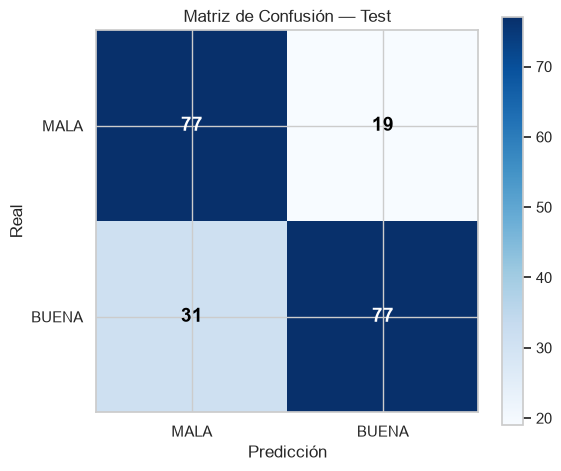

In [123]:
cm = confusion_matrix(y_test_np, preds_test)
print("\n=== Matriz de confusión (test) ===")
print(f"                    Pred MALA    Pred BUENA")
print(f"Real MALA   (0)      {cm[0,0]:5d}        {cm[0,1]:5d}")
print(f"Real BUENA  (1)      {cm[1,0]:5d}        {cm[1,1]:5d}")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks([0,1]); ax.set_xticklabels(['MALA', 'BUENA'])
ax.set_yticks([0,1]); ax.set_yticklabels(['MALA', 'BUENA'])
ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.set_title('Matriz de Confusión — Test')
for i in range(2):
    for j in range(2):
        color = 'white' if cm[i,j] > cm.max()/2 else 'black'
        ax.text(j, i, str(cm[i,j]), ha='center', va='center',
                color=color, fontsize=14, fontweight='bold')
plt.colorbar(im, ax=ax); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_matrix_test.png"), dpi=150)
plt.show()

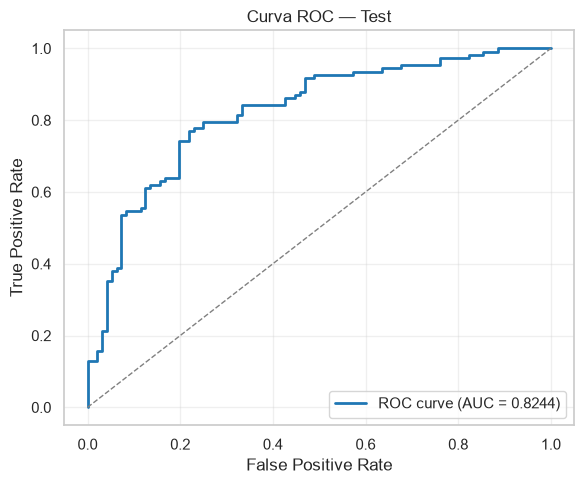

In [124]:
fpr, tpr, _ = roc_curve(y_test_np, probs_test)
auc_test = roc_auc_score(y_test_np, probs_test)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='tab:blue', lw=2,
         label=f'ROC curve (AUC = {auc_test:.4f})')
plt.plot([0,1], [0,1], color='gray', linestyle='--', lw=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Curva ROC — Test'); plt.legend(loc='lower right')
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "roc_curve_test.png"), dpi=150)
plt.show()

In [125]:
print("=== Classification Report (test) ===")
print(classification_report(y_test_np, preds_test,
                             target_names=['MALA', 'BUENA'], digits=4))

# Coeficientes del modelo final
weights = model_final.linear.weight.detach().numpy().flatten()
bias    = model_final.linear.bias.item()

coef_df = pd.DataFrame({
    'Feature': selected_features,
    'Coeficiente': weights
}).sort_values('Coeficiente', key=abs, ascending=False)

print("\n=== Coeficientes del modelo final ===")
print(coef_df.round(4).to_string(index=False))
print(f"bias: {bias:+.4f}")

=== Classification Report (test) ===
              precision    recall  f1-score   support

        MALA     0.7130    0.8021    0.7549        96
       BUENA     0.8021    0.7130    0.7549       108

    accuracy                         0.7549       204
   macro avg     0.7575    0.7575    0.7549       204
weighted avg     0.7601    0.7549    0.7549       204


=== Coeficientes del modelo final ===
             Feature  Coeficiente
             alcohol       1.0971
    volatile acidity      -0.5404
total sulfur dioxide      -0.3638
           sulphates       0.3509
         citric acid      -0.1097
             density       0.0747
bias: +0.1008


## 7. Conclusiones

- Las 6 features seleccionadas (alcohol, sulphates, volatile acidity, total sulfur dioxide, density, citric acid) coinciden en los rankings de correlación e información mutua.
- El modelo final (Adam, lr=0.001, batch=16, 150 épocas) alcanza **F1=0.75 y AUC=0.82 en test**, superando ligeramente el desempeño en validación.
- No se observa overfitting: las curvas train/val convergen y test tiene métricas ≥ val.
- El coeficiente más importante es `alcohol` (+1.10), seguido de `volatile acidity` (−0.54).
- Trabajo futuro: probar modelos no lineales (Random Forest, XGBoost) y agregar interacciones entre features.